In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("EV Battery Health Predictor")
print("Libraries loaded successfully!")

EV Battery Health Predictor
Libraries loaded successfully!


In [2]:

battery_data = pd.DataFrame({
    "Cycle": [1, 50, 100, 150, 200, 250, 300],
    "Capacity_Ah": [2.00, 1.97, 1.93, 1.89, 1.84, 1.79, 1.73],
    "Temperature_C": [25, 26, 27, 28, 29, 30, 31]
})

battery_data["SOH_Percent"] = (
    battery_data["Capacity_Ah"] / battery_data["Capacity_Ah"].iloc[0]
) * 100

print(battery_data.round(2))

   Cycle  Capacity_Ah  Temperature_C  SOH_Percent
0      1         2.00             25        100.0
1     50         1.97             26         98.5
2    100         1.93             27         96.5
3    150         1.89             28         94.5
4    200         1.84             29         92.0
5    250         1.79             30         89.5
6    300         1.73             31         86.5


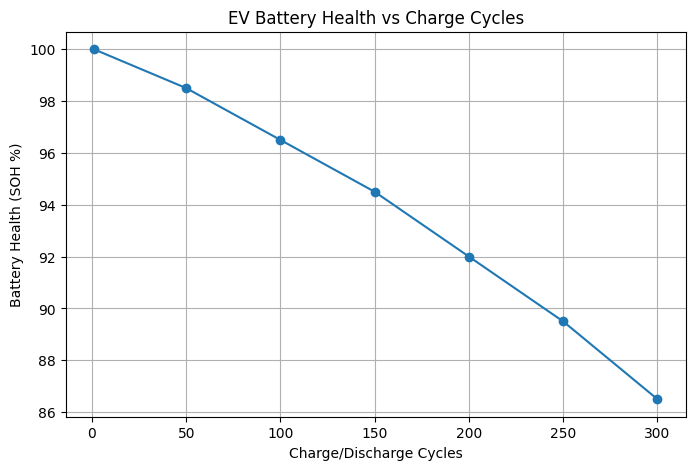

In [3]:

plt.figure(figsize=(8, 5))

plt.plot(
    battery_data["Cycle"],
    battery_data["SOH_Percent"],
    marker="o"
)

plt.title("EV Battery Health vs Charge Cycles")
plt.xlabel("Charge/Discharge Cycles")
plt.ylabel("Battery Health (SOH %)")
plt.grid(True)

plt.show()

In [4]:
import requests
import zipfile
import io
import os

url = "https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("/content/nasa_battery_data")

print("Dataset downloaded successfully!")
print(os.listdir("/content/nasa_battery_data"))

Dataset downloaded successfully!
['5. Battery Data Set']


In [5]:
import os

folder = "/content/nasa_battery_data/5. Battery Data Set"

for root, dirs, files in os.walk(folder):
    for file in files:
        print(file)

6. BatteryAgingARC_53_54_55_56.zip
3. BatteryAgingARC_25-44.zip
4. BatteryAgingARC_45_46_47_48.zip
2. BatteryAgingARC_25_26_27_28_P1.zip
1. BatteryAgingARC-FY08Q4.zip
5. BatteryAgingARC_49_50_51_52.zip


In [6]:
import zipfile
import os

base_folder = "/content/nasa_battery_data/5. Battery Data Set"
zip_path = os.path.join(base_folder, "1. BatteryAgingARC-FY08Q4.zip")

extract_folder = "/content/nasa_battery_data/battery_files"
os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_folder)

for root, dirs, files in os.walk(extract_folder):
    for file in files:
        print(file)

B0018.mat
B0006.mat
B0005.mat
README.txt
B0007.mat


In [7]:

from scipy.io import loadmat, whosmat

file_path = "/content/nasa_battery_data/battery_files/B0005.mat"

# Check the contents of the MATLAB file
print("Available data:")
print(whosmat(file_path))

# Load the battery data
mat = loadmat(file_path)

print("\nVariables inside the file:")
print([key for key in mat.keys() if not key.startswith("__")])


Available data:
[('B0005', (1, 1), 'struct')]

Variables inside the file:
['B0005']


In [8]:

battery = mat["B0005"][0, 0]

print("Battery structure fields:")
print(battery.dtype.names)

print("\nNumber of cycles:")
print(len(battery["cycle"][0]))

Battery structure fields:
('cycle',)

Number of cycles:
616


In [9]:

cycles = battery["cycle"][0]

print("First cycle details:")
print(cycles[0].dtype.names)

print("\nFirst cycle data:")
print(cycles[0])

First cycle details:
('type', 'ambient_temperature', 'time', 'data')

First cycle data:
(array(['charge'], dtype='<U6'), array([[24]], dtype=uint8), array([[2.0080e+03, 4.0000e+00, 2.0000e+00, 1.3000e+01, 8.0000e+00,
        1.7921e+01]]), array([[(array([[3.87301722, 3.47939356, 4.00058782, 4.01239519, 4.01970806,
                4.02540947, 4.03063627, 4.03534896, 4.03971637, 4.04354121,
                4.04672407, 4.05032083, 4.05347776, 4.05687947, 4.06020401,
                4.06309148, 4.06606364, 4.06810568, 4.07091089, 4.07314062,
                4.07531198, 4.07798651, 4.07976022, 4.08180212, 4.08379322,
                4.08535888, 4.08707793, 4.0888699 , 4.08991841, 4.09204117,
                4.09327341, 4.09462341, 4.09636787, 4.09755211, 4.09852259,
                4.09990153, 4.10107397, 4.10186053, 4.10303834, 4.10433761,
                4.10518719, 4.10617751, 4.10713402, 4.108074  , 4.10876115,
                4.10971157, 4.11073785, 4.1115377 , 4.11216994, 4.11307997,

In [10]:

# Inspect only the structure, not all the measurement values
first_cycle = cycles[0]

print("Cycle fields:")
print(first_cycle.dtype.names)

print("\nCycle type:")
print(first_cycle["type"].ravel()[:1])

print("\nData structure:")
print(first_cycle["data"].dtype.names)


Cycle fields:
('type', 'ambient_temperature', 'time', 'data')

Cycle type:
['charge']

Data structure:
('Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time')


In [11]:

# Find all discharge cycles in NASA battery data
discharge_cycles = []

for cycle in cycles:
    cycle_type = cycle["type"].item()

    if cycle_type == "discharge":
        discharge_cycles.append(cycle)

print("Total discharge cycles:", len(discharge_cycles))

print("\nFirst discharge cycle data fields:")
if discharge_cycles:
    print(discharge_cycles[0]["data"].dtype.names)

Total discharge cycles: 168

First discharge cycle data fields:
('Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity')


In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract capacity from each discharge cycle
results = []

for i, cycle in enumerate(discharge_cycles):
    capacity = float(cycle["data"][0, 0]["Capacity"][0, 0])

    results.append({
        "Discharge_Cycle": i + 1,
        "Capacity_Ah": capacity
    })

# Create DataFrame
df = pd.DataFrame(results)

# Calculate State of Health (SOH)
initial_capacity = df["Capacity_Ah"].iloc[0]
df["SOH_Percent"] = (
    df["Capacity_Ah"] / initial_capacity
) * 100

print("First 10 discharge cycles:")
print(df.head(10).round(3))

print("\nInitial capacity:", round(initial_capacity, 3), "Ah")
print("Latest capacity:", round(df["Capacity_Ah"].iloc[-1], 3), "Ah")
print("Latest SOH:", round(df["SOH_Percent"].iloc[-1], 2), "%")

First 10 discharge cycles:
   Discharge_Cycle  Capacity_Ah  SOH_Percent
0                1        1.856      100.000
1                2        1.846       99.453
2                3        1.835       98.861
3                4        1.835       98.857
4                5        1.835       98.823
5                6        1.836       98.878
6                7        1.835       98.850
7                8        1.826       98.345
8                9        1.825       98.292
9               10        1.825       98.283

Initial capacity: 1.856 Ah
Latest capacity: 1.325 Ah
Latest SOH: 71.38 %


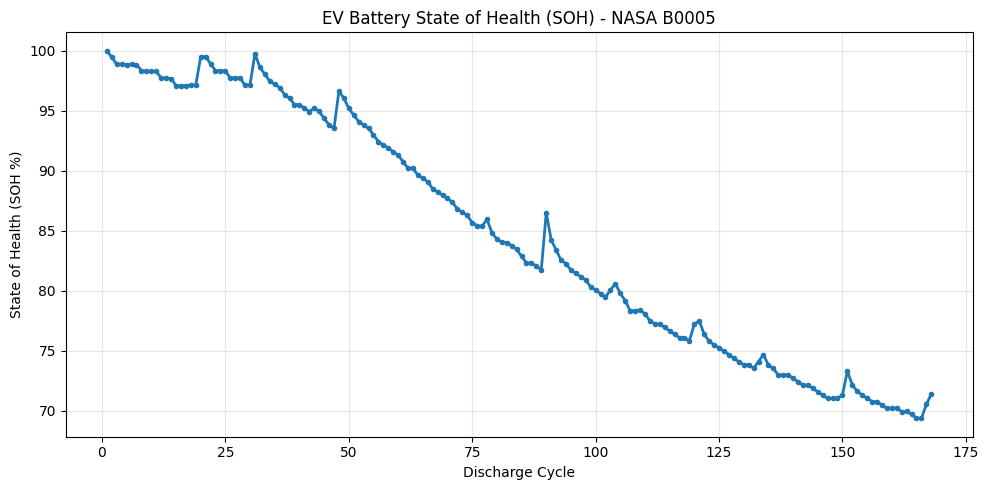

In [13]:

plt.figure(figsize=(10, 5))

plt.plot(
    df["Discharge_Cycle"],
    df["SOH_Percent"],
    marker="o",
    markersize=3,
    linewidth=2
)

plt.title("EV Battery State of Health (SOH) - NASA B0005")
plt.xlabel("Discharge Cycle")
plt.ylabel("State of Health (SOH %)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

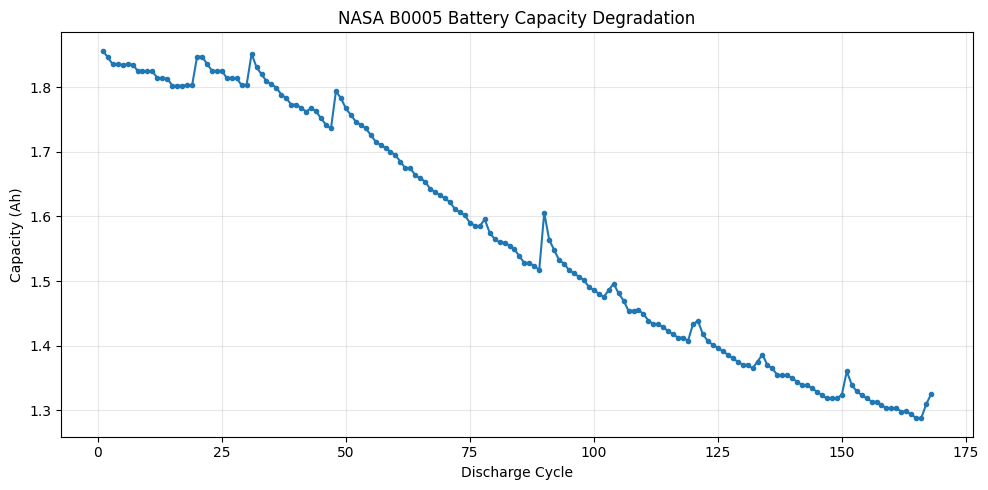

In [14]:

plt.figure(figsize=(10, 5))

plt.plot(
    df["Discharge_Cycle"],
    df["Capacity_Ah"],
    marker="o",
    markersize=3
)

plt.title("NASA B0005 Battery Capacity Degradation")
plt.xlabel("Discharge Cycle")
plt.ylabel("Capacity (Ah)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Input and target
X = df[["Discharge_Cycle"]]
y = df["SOH_Percent"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
model.fit(X_train, y_train)

# Check model performance
predictions = model.predict(X_test)

print("Model training completed!")
print("Mean Absolute Error (MAE):",
      round(mean_absolute_error(y_test, predictions), 2))
print("R2 Score:",
      round(r2_score(y_test, predictions), 3))

Model training completed!
Mean Absolute Error (MAE): 0.37
R2 Score: 0.997


In [16]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Sort cycles in chronological order
df_sorted = df.sort_values("Discharge_Cycle").reset_index(drop=True)

# First 80% for training; final 20% for testing
split_index = int(len(df_sorted) * 0.8)

train_data = df_sorted.iloc[:split_index]
test_data = df_sorted.iloc[split_index:]

X_train = train_data[["Discharge_Cycle"]]
y_train = train_data["SOH_Percent"]

X_test = test_data[["Discharge_Cycle"]]
y_test = test_data["SOH_Percent"]

# Train using earlier cycles only
future_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
future_model.fit(X_train, y_train)

# Evaluate on later cycles
future_predictions = future_model.predict(X_test)

print("Chronological test MAE:",
      round(mean_absolute_error(y_test, future_predictions), 2))
print("Chronological test R2:",
      round(r2_score(y_test, future_predictions), 3))

Chronological test MAE: 3.04
Chronological test R2: -6.461


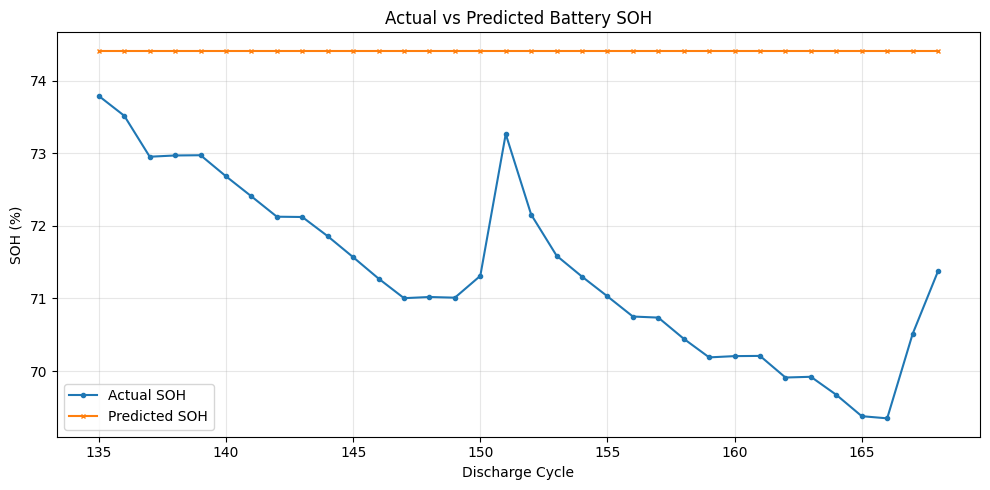

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    test_data["Discharge_Cycle"],
    y_test,
    label="Actual SOH",
    marker="o",
    markersize=3
)

plt.plot(
    test_data["Discharge_Cycle"],
    future_predictions,
    label="Predicted SOH",
    marker="x",
    markersize=3
)

plt.title("Actual vs Predicted Battery SOH")
plt.xlabel("Discharge Cycle")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Linear Regression MAE: 1.66
Linear Regression R2: -2.055


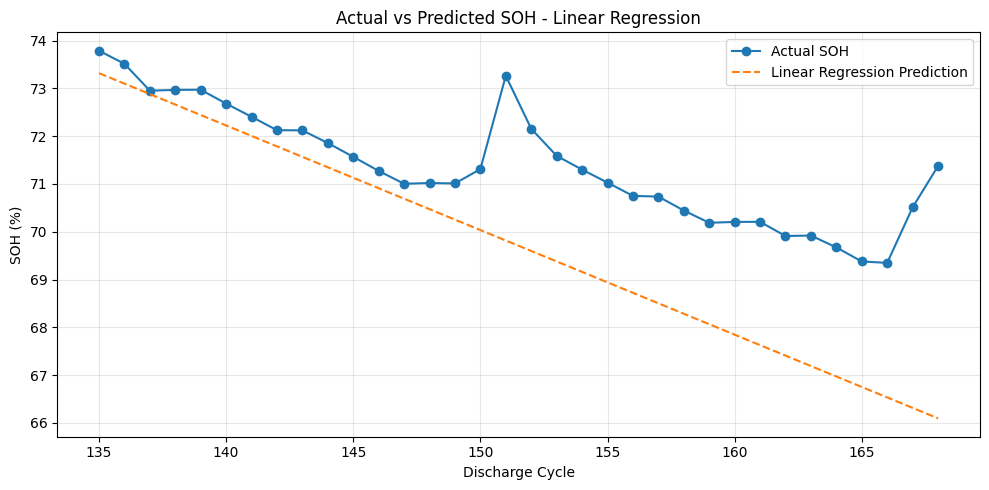

In [18]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Train using earlier cycles only
linear_model = LinearRegression()

linear_model.fit(
    train_data[["Discharge_Cycle"]],
    train_data["SOH_Percent"]
)

# Predict later cycles
linear_predictions = linear_model.predict(
    test_data[["Discharge_Cycle"]]
)

print("Linear Regression MAE:",
      round(mean_absolute_error(
          test_data["SOH_Percent"], linear_predictions
      ), 2))

print("Linear Regression R2:",
      round(r2_score(
          test_data["SOH_Percent"], linear_predictions
      ), 3))

# Plot actual vs predicted
plt.figure(figsize=(10, 5))
plt.plot(
    test_data["Discharge_Cycle"],
    test_data["SOH_Percent"],
    label="Actual SOH",
    marker="o"
)
plt.plot(
    test_data["Discharge_Cycle"],
    linear_predictions,
    label="Linear Regression Prediction",
    linestyle="--"
)

plt.title("Actual vs Predicted SOH - Linear Regression")
plt.xlabel("Discharge Cycle")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:

print("Linear Regression MAE:",
      round(mean_absolute_error(
          test_data["SOH_Percent"], linear_predictions
      ), 2))

print("Linear Regression R2:",
      round(r2_score(
          test_data["SOH_Percent"], linear_predictions
      ), 3))

Linear Regression MAE: 1.66
Linear Regression R2: -2.055


Polynomial Regression MAE: 5.13
Polynomial Regression R2: -20.821


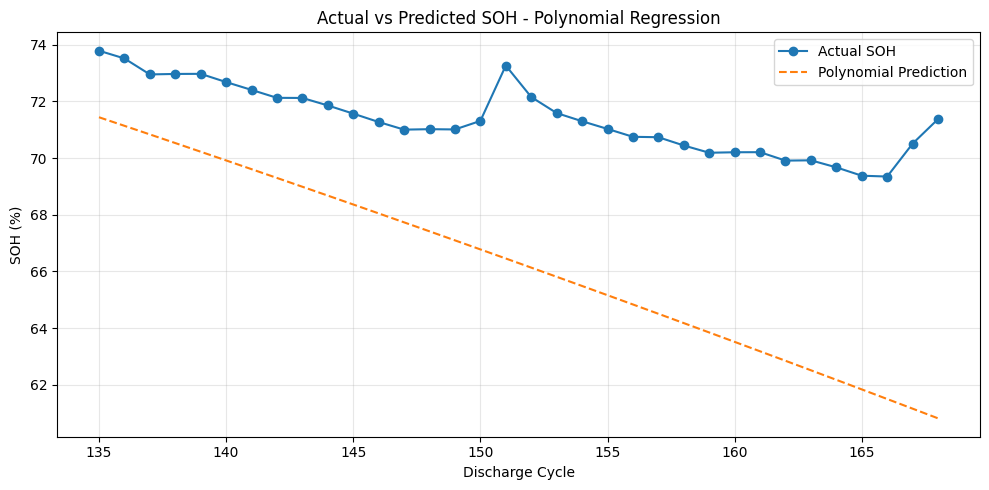

In [20]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Degree 2 polynomial model
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(
    train_data[["Discharge_Cycle"]],
    train_data["SOH_Percent"]
)

poly_predictions = poly_model.predict(
    test_data[["Discharge_Cycle"]]
)

print("Polynomial Regression MAE:",
      round(mean_absolute_error(
          test_data["SOH_Percent"], poly_predictions
      ), 2))

print("Polynomial Regression R2:",
      round(r2_score(
          test_data["SOH_Percent"], poly_predictions
      ), 3))

plt.figure(figsize=(10, 5))
plt.plot(
    test_data["Discharge_Cycle"],
    test_data["SOH_Percent"],
    label="Actual SOH",
    marker="o"
)
plt.plot(
    test_data["Discharge_Cycle"],
    poly_predictions,
    label="Polynomial Prediction",
    linestyle="--"
)
plt.title("Actual vs Predicted SOH - Polynomial Regression")
plt.xlabel("Discharge Cycle")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:

comparison = test_data[["Discharge_Cycle", "SOH_Percent"]].copy()

comparison["Predicted_SOH"] = linear_predictions
comparison["Absolute_Error"] = abs(
    comparison["SOH_Percent"] - comparison["Predicted_SOH"]
)

print(comparison.head(10).round(2).to_string(index=False))

print("\nAverage absolute error:",
      round(comparison["Absolute_Error"].mean(), 2))

 Discharge_Cycle  SOH_Percent  Predicted_SOH  Absolute_Error
             135        73.79          73.32            0.47
             136        73.51          73.10            0.42
             137        72.95          72.88            0.07
             138        72.97          72.66            0.31
             139        72.97          72.44            0.53
             140        72.68          72.22            0.46
             141        72.40          72.00            0.40
             142        72.12          71.79            0.34
             143        72.12          71.57            0.55
             144        71.86          71.35            0.51

Average absolute error: 1.66


In [22]:

import numpy as np

# Enter a discharge cycle number
cycle_number = int(input("Enter discharge cycle number: "))

if cycle_number < 1:
    print("Please enter a positive cycle number.")

elif cycle_number > df["Discharge_Cycle"].max():
    print("This cycle is outside the recorded dataset.")
    print("For this model, enter a cycle from 1 to",
          int(df["Discharge_Cycle"].max()))

else:
    predicted_soh = linear_model.predict(
        pd.DataFrame({"Discharge_Cycle": [cycle_number]})
    )[0]

    print("Cycle Number:", cycle_number)
    print("Estimated Battery SOH:",
          round(float(predicted_soh), 2), "%")
    print("Note: This is a model estimate, not a battery diagnostic.")

Enter discharge cycle number: 150
Cycle Number: 150
Estimated Battery SOH: 70.04 %
Note: This is a model estimate, not a battery diagnostic.
